In [1]:
import numpy as np
import matplotlib.pyplot as plt

from flowmap.flowmap_embedding import VectorFieldEmbedder
from flowmap.plot import *


# --------------------------
# Expression normalization
# --------------------------
def normalize_expression(X):
    X = X.astype(float)

    libsize = X.sum(axis=1, keepdims=True)
    libsize[libsize == 0] = 1.0
    X = X / libsize * 1e4

    return np.log1p(X)


# --------------------------
# Main runner
# --------------------------
def flowmap_run_single(
    dataset_name,
    cfg,
    stream_density=0.7,
    streamline_thickness=1.0,
    arrowsize=2.5,
    scatter_size=200,
    scatter_alpha=0.15,
):

    print(f"\n=== Running FlowMap on: {dataset_name} ===")

    # ---- Load ----
    S = np.load(cfg["S"])
    V = np.load(cfg["V"])
    color = np.load(cfg["color"])
    X_emb = np.load(cfg["embedding"])
    valid_genes = np.isfinite(V).all(axis=0)
    print(f"Keeping {valid_genes.sum()} / {V.shape[1]} genes (valid velocity)")
    
    S = S[:, valid_genes]
    V = V[:, valid_genes]

    # ---- Normalize expression ONLY ----
    S = normalize_expression(S)

    # ---- Clean color ----
    color = np.asarray(color, dtype=float).ravel()
    color = np.nan_to_num(color, nan=0.0)

    if color.max() > color.min():
        color = (color - color.min()) / (color.max() - color.min())
    else:
        color = np.zeros_like(color)

    # ---- FlowMap ----
    emb = VectorFieldEmbedder(
        S,
        V,
        method="umap",
        dist_method="phase",
        X_emb=X_emb,  # fixed embedding
        embed_kwargs={"n_neighbors": 30, "min_dist": 0.6},
        dof=30,
        use_PCA=True,
    )

    emb.fit_embedding(seed=0)

    # ---- Plot ----
    plot_velocity_stream(
        X_2d=emb.X_emb,
        spline=emb.spline_vf,
        scatter_color=color,
        cmap="viridis",
        show_colorbar=False,
        show_axes=False,
        stream_density=stream_density,
        streamline_thickness=streamline_thickness,
        arrowsize=arrowsize,
        scatter_size=scatter_size,
        scatter_alpha=scatter_alpha,
        figsize=(6, 5),
    )

    return emb

/Users/jh/micromamba/envs/flowmap-manuscript/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



=== Running FlowMap on: stochastic ===
Keeping 2000 / 2000 genes (valid velocity)
[PCA] Projecting to 30 components …
[Spline] Fitting manifold spline on 2930 cells …
[Spline] Using all 2930 points as control points.
[Spline] Mapping vector field …
[Spline] Fitting velocity spline …
[Spline] Using all 2930 points as control points.
[FlowMap] Done.

=== Running FlowMap on: dynamical ===
Keeping 954 / 2000 genes (valid velocity)
[PCA] Projecting to 30 components …
[Spline] Fitting manifold spline on 2930 cells …
[Spline] Using all 2930 points as control points.
[Spline] Mapping vector field …
[Spline] Fitting velocity spline …
[Spline] Using all 2930 points as control points.
[FlowMap] Done.

=== Running FlowMap on: dynamo ===
Keeping 2000 / 2000 genes (valid velocity)
[PCA] Projecting to 30 components …
[Spline] Fitting manifold spline on 2930 cells …
[Spline] Using all 2930 points as control points.
[Spline] Mapping vector field …
[Spline] Fitting velocity spline …
[Spline] Using all 

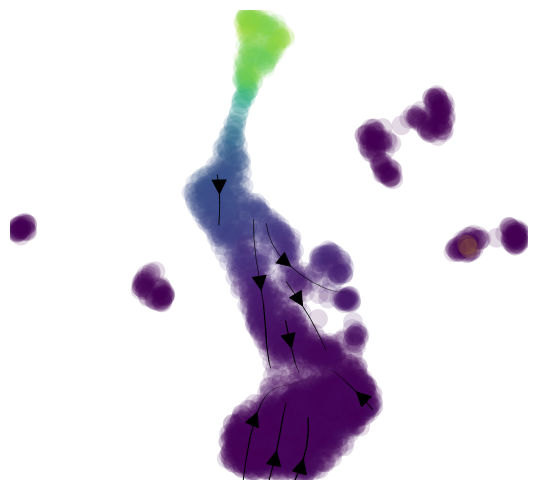

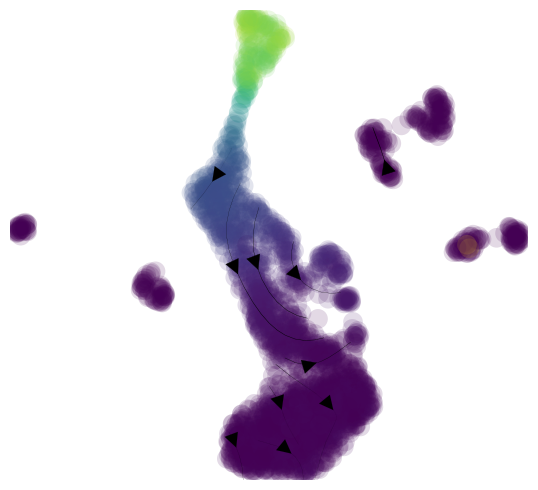

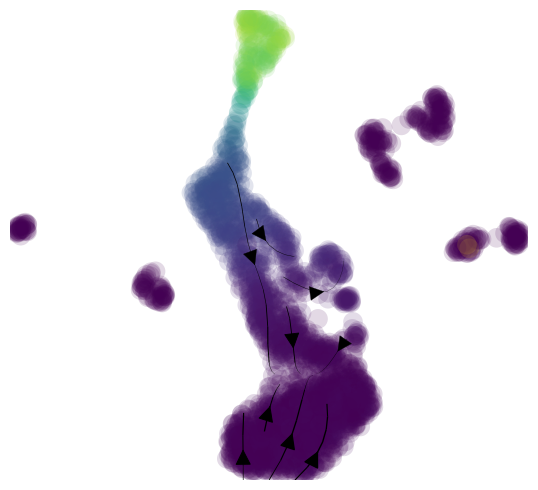

In [2]:
base_cfg = {
    "S": "./intermediate_data/benchmark/velocity_estimation/dentate_gyrus/spliced.npy",
    "embedding": "./intermediate_data/benchmark/velocity_estimation/dentate_gyrus/embedding.npy",
    "color": "./intermediate_data/benchmark/velocity_estimation/dentate_gyrus/pseudotime.npy",
}

# stochastic
cfg = base_cfg.copy()
cfg["V"] = "./intermediate_data/benchmark/velocity_estimation/dentate_gyrus/V_stochastic.npy"
emb_stoch = flowmap_run_single("stochastic", cfg)

# dynamical
cfg = base_cfg.copy()
cfg["V"] = "./intermediate_data/benchmark/velocity_estimation/dentate_gyrus/V_dynamical.npy"
emb_dyn = flowmap_run_single("dynamical", cfg)

# dynamo
cfg = base_cfg.copy()
cfg["V"] = "./intermediate_data/benchmark/velocity_estimation/dentate_gyrus/V_dynamo.npy"
emb_dynamo = flowmap_run_single("dynamo", cfg)

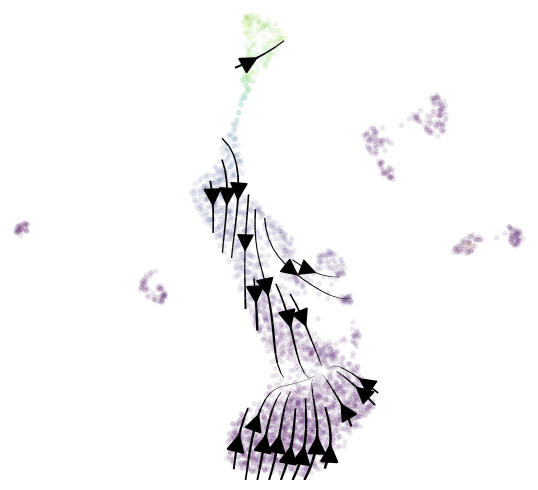

In [3]:
# --------------------------
# Common settings
# --------------------------
stream_density = 1.5
streamline_thickness = 1.9
arrowsize = 2.8
scatter_size = 15
scatter_alpha = 0.1

color = np.load(base_cfg["color"])
color = np.asarray(color, dtype=float).ravel()
color = np.nan_to_num(color, nan=0.0)
color = (color - color.min()) / (color.max() - color.min() + 1e-8)

# --------------------------
# Stochastic
# --------------------------
fig=plot_velocity_stream(
    X_2d=emb_stoch.X_emb,
    spline=emb_stoch.spline_vf,
    scatter_color=color,
    cmap="viridis",
    show_colorbar=False,
    show_axes=False,
    stream_density=stream_density,
    streamline_thickness=streamline_thickness,
    arrowsize=arrowsize,
    scatter_size=scatter_size,
    scatter_alpha=scatter_alpha,
    figsize=(6, 5),
)

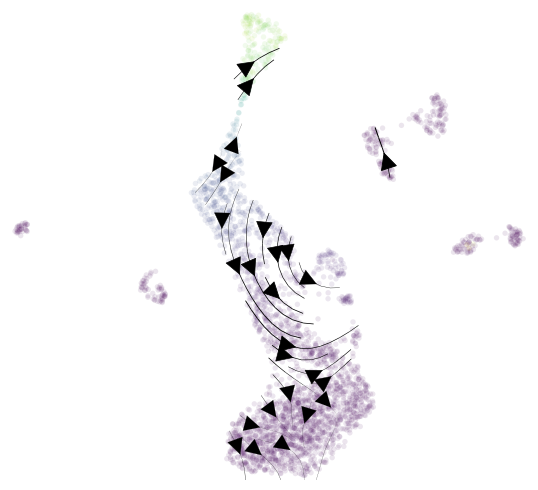

In [4]:
# --------------------------
# Dynamical
# --------------------------
fig = plot_velocity_stream(
    X_2d=emb_dyn.X_emb,
    spline=emb_dyn.spline_vf,
    scatter_color=color,
    cmap="viridis",
    show_colorbar=False,
    show_axes=False,
    stream_density=stream_density,
    streamline_thickness=streamline_thickness,
    arrowsize=arrowsize,
    scatter_size=scatter_size,
    scatter_alpha=scatter_alpha,
    figsize=(6, 5),
)

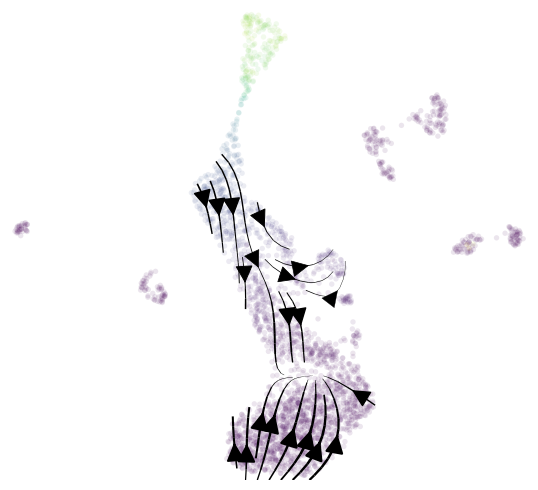

In [5]:
# --------------------------
# Dynamo
# --------------------------
fig = plot_velocity_stream(
    X_2d=emb_dynamo.X_emb,
    spline=emb_dynamo.spline_vf,
    scatter_color=color,
    cmap="viridis",
    show_colorbar=False,
    show_axes=False,
    stream_density=stream_density,
    streamline_thickness=streamline_thickness,
    arrowsize=arrowsize,
    scatter_size=scatter_size,
    scatter_alpha=scatter_alpha,
    figsize=(6, 5),
)

/var/folders/t4/_r2_dq3102ngn00yhxg8zdlm0000gn/T/ipykernel_61176/1079946759.py:50: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


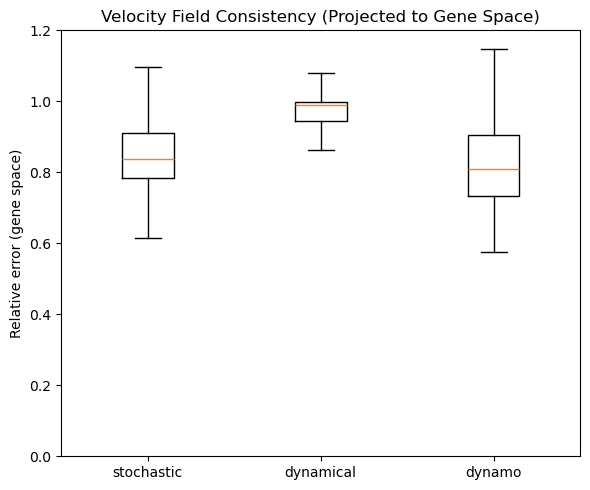

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------
# Relative error
# --------------------------
def cell_error(V_true, V_pred):
    num = np.linalg.norm(V_true - V_pred, axis=1)
    denom = np.linalg.norm(V_true, axis=1) + 1e-8
    return num / denom


# --------------------------
# Stochastic
# --------------------------
V_emb_pred = emb_stoch.spline_vf.predict(emb_stoch.X_emb)
J = emb_stoch.spline.compute_jacobians(emb_stoch.X_emb)
V_pred_stoch = np.einsum("ngd,nd->ng", J, V_emb_pred)

err_stoch = cell_error(emb_stoch.V, V_pred_stoch)


# --------------------------
# Dynamical
# --------------------------
V_emb_pred = emb_dyn.spline_vf.predict(emb_dyn.X_emb)
J = emb_dyn.spline.compute_jacobians(emb_dyn.X_emb)
V_pred_dyn = np.einsum("ngd,nd->ng", J, V_emb_pred)

err_dyn = cell_error(emb_dyn.V, V_pred_dyn)


# --------------------------
# Dynamo
# --------------------------
V_emb_pred = emb_dynamo.spline_vf.predict(emb_dynamo.X_emb)
J = emb_dynamo.spline.compute_jacobians(emb_dynamo.X_emb)
V_pred_dynamo = np.einsum("ngd,nd->ng", J, V_emb_pred)

err_dynamo = cell_error(emb_dynamo.V, V_pred_dynamo)


# --------------------------
# Violin plot
# --------------------------
plt.figure(figsize=(6, 5))

data = [err_stoch, err_dyn, err_dynamo]

plt.boxplot(
    data,
    labels=["stochastic", "dynamical", "dynamo"],
    showfliers=False,
)

plt.ylabel("Relative error (gene space)")
plt.title("Velocity Field Consistency (Projected to Gene Space)")

# ✅ normal decimal scale (remove log)
# (just don’t call plt.yscale("log"))

# optional: limit range for better readability
plt.ylim(0, 1.2)

plt.tight_layout()
plt.show()

In [7]:
%load_ext autoreload
%autoreload 2
    
import numpy as np
import matplotlib.pyplot as plt

from flowmap.flowmap_embedding import VectorFieldEmbedder
from flowmap.plot import plot_velocity_stream


# --------------------------
# Main runner (NO normalization)
# --------------------------
def flowmap_run_single(
    dataset_name,
    cfg,
    stream_density=1.2,
    streamline_thickness=1.2,
    arrowsize=2.8,
    scatter_size=20,
    scatter_alpha=0.6,
):

    print(f"\n=== Running FlowMap on: {dataset_name} ===")

    # ---- Load ----
    S = np.load(cfg["S"]).astype(float)
    V = np.load(cfg["V"]).astype(float)
    color = np.load(cfg["color"])
    X_emb = np.load(cfg["embedding"])

    # ---- Remove genes with invalid velocity ----
    nan_frac = np.isnan(V).mean(axis=0)
    valid_genes = nan_frac < 0.01
    print(f"Keeping {valid_genes.sum()} / {V.shape[1]} genes (valid velocity)")

    S = S[:, valid_genes]
    V = V[:, valid_genes]

    # ---- Final safety cleanup ----
    S = np.nan_to_num(S, nan=0.0)
    V = np.nan_to_num(V, nan=0.0)

    # ---- Clean color ----
    color = np.asarray(color, dtype=float).ravel()
    color = np.nan_to_num(color, nan=0.0)
    if color.max() > color.min():
        color = (color - color.min()) / (color.max() - color.min())
    else:
        color = np.zeros_like(color)

    # ---- FlowMap (NO PCA, NO re-embedding) ----
    emb = VectorFieldEmbedder(
        S,
        V,
        method="umap",
        dist_method="phase",
        X_emb=X_emb,  # fixed embedding
        embed_kwargs={"n_neighbors": 30, "min_dist": 0.6},
        dof=30,
        use_PCA=True,
        n_spline_points=4000
    )

    emb.fit_embedding(seed=0)

    # ---- Plot ----
    plot_velocity_stream(
        X_2d=emb.X_emb,
        spline=emb.spline_vf,
        scatter_color=color,
        cmap="viridis",
        show_colorbar=False,
        show_axes=False,
        stream_density=stream_density,
        streamline_thickness=streamline_thickness,
        arrowsize=arrowsize,
        scatter_size=scatter_size,
        scatter_alpha=scatter_alpha,
        figsize=(6, 5),
    )

    return emb


=== Running FlowMap on: stochastic ===
Keeping 2000 / 2000 genes (valid velocity)
[PCA] Projecting to 30 components …
[Spline] Fitting manifold spline on 4000 cells …
[Spline] Using all 4000 points as control points.
[Spline] Mapping vector field …
[Spline] Fitting velocity spline …
[Spline] Using all 4000 points as control points.
[FlowMap] Done.

=== Running FlowMap on: dynamical ===
Keeping 2000 / 2000 genes (valid velocity)
[PCA] Projecting to 30 components …
[Spline] Fitting manifold spline on 4000 cells …
[Spline] Using all 4000 points as control points.
[Spline] Mapping vector field …
[Spline] Fitting velocity spline …
[Spline] Using all 4000 points as control points.
[FlowMap] Done.

=== Running FlowMap on: dynamo ===
Keeping 2000 / 2000 genes (valid velocity)
[PCA] Projecting to 30 components …
[Spline] Fitting manifold spline on 4000 cells …
[Spline] Using all 4000 points as control points.
[Spline] Mapping vector field …
[Spline] Fitting velocity spline …
[Spline] Using all

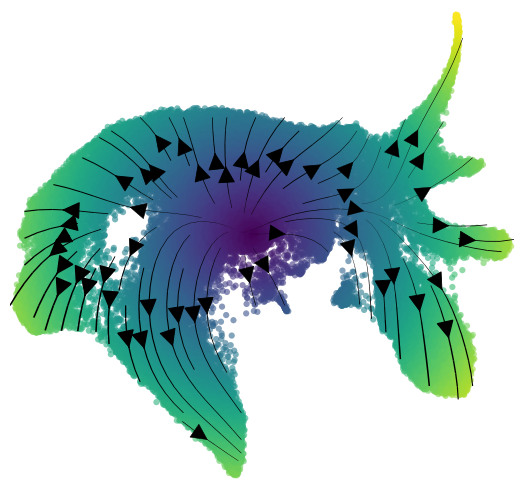

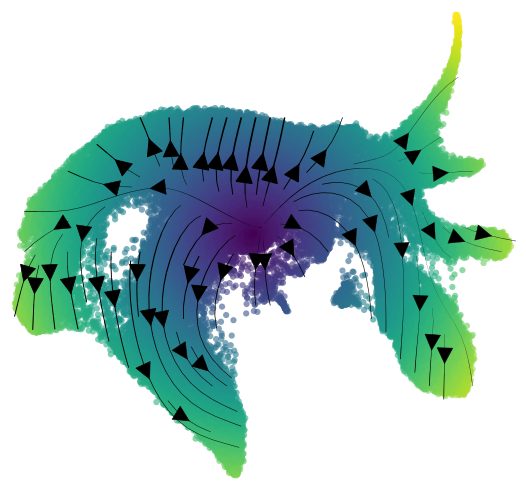

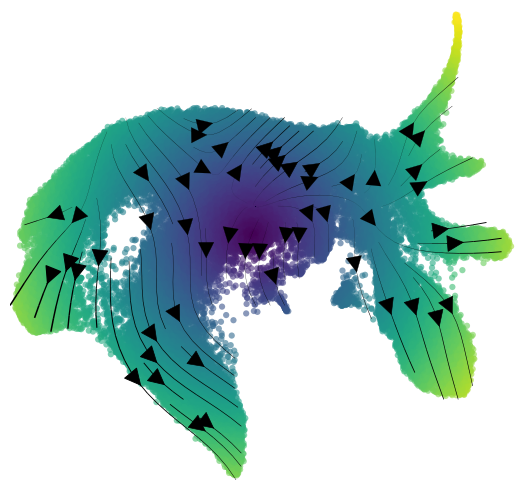

In [8]:
base_cfg = {
    "S": "./intermediate_data/benchmark/velocity_estimation/larry/spliced.npy",
    "embedding": "./intermediate_data/benchmark/velocity_estimation/larry/embedding.npy",
    "color": "./intermediate_data/benchmark/velocity_estimation/larry/distance_pseudotime.npy",
}

# stochastic
cfg = base_cfg.copy()
cfg["V"] = "./intermediate_data/benchmark/velocity_estimation/larry/velocity_stochastic.npy"
emb_stoch = flowmap_run_single("stochastic", cfg)

# dynamical
cfg = base_cfg.copy()
cfg["V"] = "./intermediate_data/benchmark/velocity_estimation/larry/velocity_dynamical.npy"
emb_dyn = flowmap_run_single("dynamical", cfg)

# dynamo
cfg = base_cfg.copy()
cfg["V"] = "./intermediate_data/benchmark/velocity_estimation/larry/V_dynamo.npy"
emb_dynamo = flowmap_run_single("dynamo", cfg)

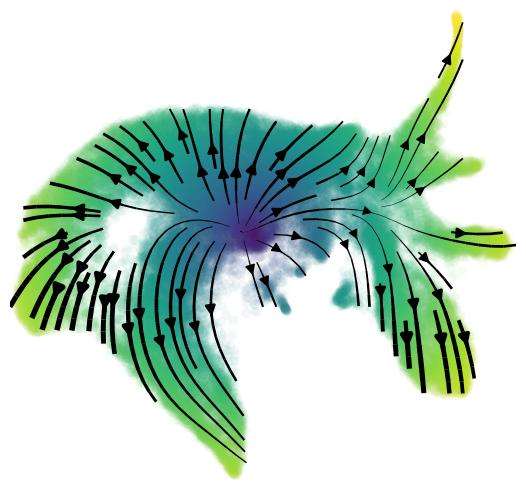

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from flowmap.plot import *

# --------------------------
# Load + normalize color
# --------------------------
color = np.load("./intermediate_data/benchmark/velocity_estimation/larry/distance_pseudotime.npy")

color = np.asarray(color, dtype=float).ravel()
valid = ~np.isnan(color)

color_norm = np.full_like(color, np.nan, dtype=float)

if valid.sum() > 0:
    c = color[valid]
    c = (c - c.min()) / (c.max() - c.min() + 1e-8)

    # 🔥 shift toward yellow (boost high values)
    c = np.clip(c**0.6, 0, 1)

    color_norm[valid] = c


# --------------------------
# Plot: stochastic
# --------------------------
fig=plot_velocity_stream(
    X_2d=emb_stoch.X_emb,
    spline=emb_stoch.spline_vf,
    scatter_color=color_norm,
    cmap="viridis",
    show_colorbar=False,
    show_axes=False,
    stream_density=1.3,
    streamline_thickness=4.0,
    arrowsize=1.5,
    scatter_size=50,
    scatter_alpha=0.05,
    figsize=(6, 5),
)

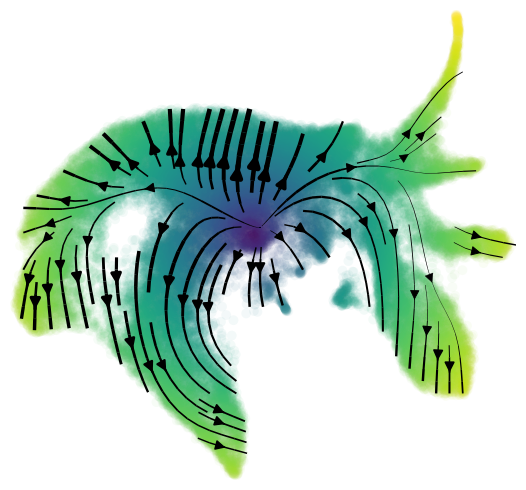

In [10]:
# --------------------------
# Plot: dynamical
# --------------------------
fig=plot_velocity_stream(
    X_2d=emb_dyn.X_emb,
    spline=emb_dyn.spline_vf,
    scatter_color=color_norm,
    cmap="viridis",
    show_colorbar=False,
    show_axes=False,
    stream_density=1.3,
    streamline_thickness=4.0,
    arrowsize=1.5,
    scatter_size=50,
    scatter_alpha=0.05,
    figsize=(6, 5),
)

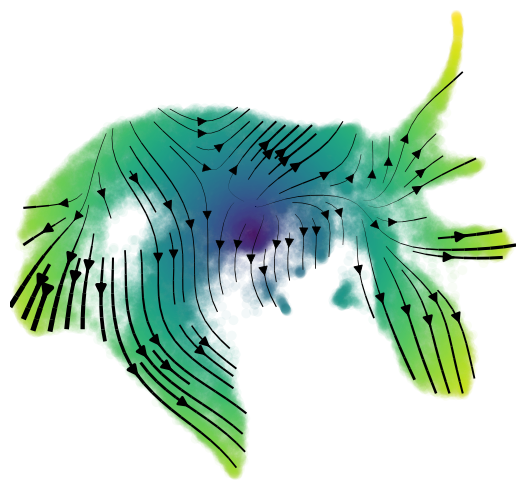

In [11]:
# --------------------------
# Plot: dynamo
# --------------------------
fig=plot_velocity_stream(
    X_2d=emb_dynamo.X_emb,
    spline=emb_dynamo.spline_vf,
    scatter_color=color_norm,
    cmap="viridis",
    show_colorbar=False,
    show_axes=False,
    stream_density=1.3,
    streamline_thickness=4.0,
    arrowsize=1.5,
    scatter_size=50,
    scatter_alpha=0.05,
    figsize=(6, 5),
)

/var/folders/t4/_r2_dq3102ngn00yhxg8zdlm0000gn/T/ipykernel_61176/1079946759.py:50: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


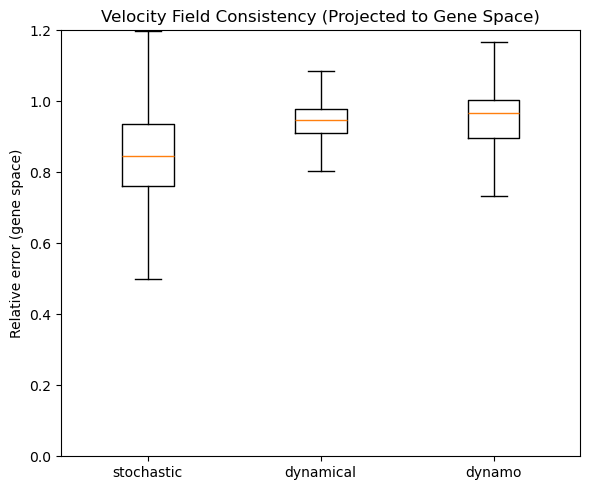

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------
# Relative error
# --------------------------
def cell_error(V_true, V_pred):
    num = np.linalg.norm(V_true - V_pred, axis=1)
    denom = np.linalg.norm(V_true, axis=1) + 1e-8
    return num / denom


# --------------------------
# Stochastic
# --------------------------
V_emb_pred = emb_stoch.spline_vf.predict(emb_stoch.X_emb)
J = emb_stoch.spline.compute_jacobians(emb_stoch.X_emb)
V_pred_stoch = np.einsum("ngd,nd->ng", J, V_emb_pred)

err_stoch = cell_error(emb_stoch.V, V_pred_stoch)


# --------------------------
# Dynamical
# --------------------------
V_emb_pred = emb_dyn.spline_vf.predict(emb_dyn.X_emb)
J = emb_dyn.spline.compute_jacobians(emb_dyn.X_emb)
V_pred_dyn = np.einsum("ngd,nd->ng", J, V_emb_pred)

err_dyn = cell_error(emb_dyn.V, V_pred_dyn)


# --------------------------
# Dynamo
# --------------------------
V_emb_pred = emb_dynamo.spline_vf.predict(emb_dynamo.X_emb)
J = emb_dynamo.spline.compute_jacobians(emb_dynamo.X_emb)
V_pred_dynamo = np.einsum("ngd,nd->ng", J, V_emb_pred)

err_dynamo = cell_error(emb_dynamo.V, V_pred_dynamo)


# --------------------------
# Violin plot
# --------------------------
plt.figure(figsize=(6, 5))

data = [err_stoch, err_dyn, err_dynamo]

plt.boxplot(
    data,
    labels=["stochastic", "dynamical", "dynamo"],
    showfliers=False,
)

plt.ylabel("Relative error (gene space)")
plt.title("Velocity Field Consistency (Projected to Gene Space)")

# ✅ normal decimal scale (remove log)
# (just don’t call plt.yscale("log"))

# optional: limit range for better readability
plt.ylim(0, 1.2)

plt.tight_layout()
plt.show()

In [13]:
from flowmap.evaluation.spline_fit_evaluator import SplineFitEvaluator

# --------------------------
# Fit gene-level splines
# --------------------------
emb_stoch.fit_gene_level_splines()
emb_dyn.fit_gene_level_splines()
emb_dynamo.fit_gene_level_splines()

[Spline-Gene] Fitting expression spline on 4000 cells …
[Spline] Using all 4000 points as control points.
[Spline-Gene] Mapping velocities …
[Spline-Gene] Fitting velocity spline …
[Spline] Using all 4000 points as control points.
[Spline-Gene] Done. X_gene (49302, 2000), V_gene (49302, 2000)
[Spline-Gene] Fitting expression spline on 4000 cells …
[Spline] Using all 4000 points as control points.
[Spline-Gene] Mapping velocities …
[Spline-Gene] Fitting velocity spline …
[Spline] Using all 4000 points as control points.
[Spline-Gene] Done. X_gene (49302, 2000), V_gene (49302, 2000)
[Spline-Gene] Fitting expression spline on 4000 cells …
[Spline] Using all 4000 points as control points.
[Spline-Gene] Mapping velocities …
[Spline-Gene] Fitting velocity spline …
[Spline] Using all 4000 points as control points.
[Spline-Gene] Done. X_gene (49302, 2000), V_gene (49302, 2000)


In [14]:
# --------------------------
# Evaluate each method
# --------------------------

N_sub = 5000
idx = np.random.choice(emb_stoch.X_emb.shape[0], N_sub, replace=False)

eval_stoch = SplineFitEvaluator(emb_stoch, mode="gene").evaluate(cell_idx=idx)
eval_dyn = SplineFitEvaluator(emb_dyn, mode="gene").evaluate(cell_idx=idx)
eval_dynamo = SplineFitEvaluator(emb_dynamo, mode="gene").evaluate(cell_idx=idx)

r2_stoch = np.array(eval_stoch["vel_r2_gene"])
r2_dyn = np.array(eval_dyn["vel_r2_gene"])
r2_dynamo = np.array(eval_dynamo["vel_r2_gene"])

In [15]:
eval_stoch["V_pred"]

array([[ 0.095072  , -0.25594875, -0.00324411, ...,  0.07238531,
        -0.12580204, -0.1008773 ],
       [ 0.00661273,  0.02443401,  0.01265171, ..., -0.00832614,
        -0.01366504,  0.05443664],
       [-0.01023019,  0.02959703,  0.00151985, ...,  0.01146252,
        -0.002865  ,  0.00488287],
       ...,
       [-0.03927415, -0.02103753, -0.01425586, ...,  0.00972411,
         0.05617016, -0.02048941],
       [ 0.02865552,  0.01853138, -0.01297316, ..., -0.00668499,
        -0.04497076,  0.01977615],
       [ 0.00209647,  0.05951497, -0.01042609, ..., -0.09184493,
        -0.04853323, -0.00315696]], shape=(5000, 2000))

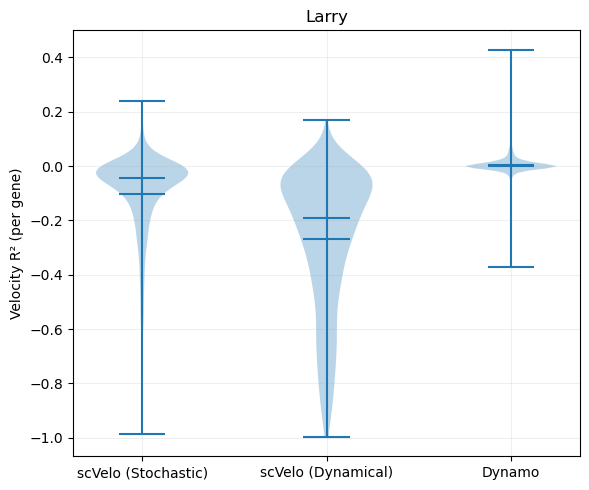

In [16]:
def clean_r2(x):
    x = x[np.isfinite(x)]
    x = x[(x > -1) & (x < 1)]  # optional: remove crazy outliers
    return x

r2_stoch = clean_r2(r2_stoch)
r2_dyn = clean_r2(r2_dyn)
r2_dynamo = clean_r2(r2_dynamo)

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.violinplot(
    [r2_stoch, r2_dyn, r2_dynamo],
    showmeans=True,
    showmedians=True,
)

plt.xticks([1, 2, 3], ["scVelo (Stochastic)", "scVelo (Dynamical)", "Dynamo"])
plt.ylabel("Velocity R² (per gene)")
plt.title("Larry")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()